# Train your model

Install the checkout's notebook dependencies first, following the README's
**Run notebooks locally** instructions. Select the `GreatAI (local)` kernel.
The default run uses a balanced subset of the bundled MAG data for speed.
Set `GREAT_AI_NOTEBOOK_FULL=1` before starting Jupyter to use the full splits.
Local subset results differ from the historical full-dataset results below.

## Local setup

Use Python 3.12 or 3.13 and install this checkout with `uv pip install --editable '.[notebooks]'`.
See **Run notebooks locally** in the repository README for the kernel, execution order,
and full-data options. Run related notebooks from the same working directory
to share the default `.cache/` model store and `tracing_database.json` database.


In [1]:
from docs.notebook_support import DATA_DIR, FULL_RUN, mag_lines

In [2]:
# Dependencies are installed once in the environment; no in-kernel installation needed.

First, we have to get some data. After downloading it [from here](https://github.com/allenai/scibert/tree/master/data/text_classification/mag), we might notice that the dataset is in [JSON Lines](https://jsonlines.org/) format (each line is a separate JSON document). 

Let's write a function which takes a single line and returns the sentence and the corresponding label from it. Before returning, the sentence is also [cleaned](https://great-ai.schmelczer.dev/reference/utilities/#great_ai.utilities.clean.clean) to remove any LaTeX, XML, unicode, PDF-extraction artifacts.

In [3]:
import json
from great_ai.utilities import clean


def preprocess(line):
    data_point = json.loads(line)

    sentence = data_point["text"]
    label = data_point["label"]

    return clean(sentence), label

Now, we can load the dataset and extract the *training* samples from it. Since we're impatient, we can do it in parallel using the [`simple_parallel_map`](https://great-ai.schmelczer.dev/reference/utilities/#great_ai.utilities.simple_parallel_map) function.

> Open files in Python are iterable: in text mode, each iteration returns the next line.

In [4]:
from great_ai.utilities import simple_parallel_map

training_lines = mag_lines(DATA_DIR / "train.txt", None if FULL_RUN else 100)
training_data = simple_parallel_map(preprocess, training_lines, concurrency=2)
X_train = [d[0] for d in training_data]
y_train = [d[1] for d in training_data]

  0%|          | 0/700 [00:00<?, ?it/s]

  0%|          | 1/700 [00:00<01:30,  7.74it/s]

 10%|█         | 71/700 [00:00<00:01, 352.47it/s]

 20%|██        | 141/700 [00:00<00:01, 467.83it/s]

 27%|██▋       | 190/700 [00:00<00:01, 475.11it/s]

 34%|███▍      | 239/700 [00:00<00:00, 461.41it/s]

 45%|████▌     | 316/700 [00:00<00:00, 538.41it/s]

 53%|█████▎    | 371/700 [00:00<00:00, 523.75it/s]

 61%|██████    | 424/700 [00:00<00:00, 504.26it/s]

 80%|████████  | 561/700 [00:01<00:00, 697.72it/s]

 90%|█████████ | 631/700 [00:01<00:00, 675.11it/s]

100%|██████████| 700/700 [00:01<00:00, 603.58it/s]

Let's do the same for the *test* data.

In [5]:
test_lines = mag_lines(DATA_DIR / "test.txt", None if FULL_RUN else 30)
test_data = simple_parallel_map(preprocess, test_lines, concurrency=2)
X_test = [d[0] for d in test_data]
y_test = [d[1] for d in test_data]

  0%|          | 0/210 [00:00<?, ?it/s]

  0%|          | 1/210 [00:00<00:27,  7.72it/s]

  6%|▌         | 12/210 [00:00<00:03, 61.14it/s]

 16%|█▌        | 34/210 [00:00<00:01, 124.86it/s]

 27%|██▋       | 56/210 [00:00<00:00, 156.07it/s]

 37%|███▋      | 78/210 [00:00<00:00, 175.16it/s]

 46%|████▌     | 96/210 [00:00<00:00, 173.89it/s]

 58%|█████▊    | 122/210 [00:00<00:00, 197.51it/s]

 69%|██████▊   | 144/210 [00:00<00:00, 202.19it/s]

 84%|████████▍ | 177/210 [00:00<00:00, 231.71it/s]

 96%|█████████▌| 201/210 [00:01<00:00, 230.89it/s]

100%|██████████| 210/210 [00:01<00:00, 191.75it/s]

After obtaining some clean data, it's time to create and train a model on it. We are going to use [scikit-learn](https://scikit-learn.org/stable/auto_examples/classification/plot_classifier_comparison.html) for this purpose.

In this case, we opted for a [linear Support Vector Machine](https://scikit-learn.org/stable/modules/generated/sklearn.svm.LinearSVC.html) because it's known to be an adequate baseline for simple classification tasks.

In [6]:
from sklearn.pipeline import make_pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC

model = make_pipeline(TfidfVectorizer(), LinearSVC(random_state=42))
# todo: hyperparameter-optimisation
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('tfidfvectorizer', ...), ('linearsvc', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[<U10](7,)","['business','economics','geography',...,'politics','psychology', 'sociology']"
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'
,"decode_error decode_error: {'strict', 'ignore', 'replace'}, default='strict'Instruction on what to do if a byte sequence is given to analyze thatcontains characters not of the given `encoding`. By default, it is'strict', meaning that a UnicodeDecodeError will be raised. Othervalues are 'ignore' and 'replace'.",'strict'
,"strip_accents strip_accents: {'ascii', 'unicode'} or callable, default=NoneRemove accents and perform other character normalizationduring the preprocessing step.'ascii' is a fast method that only works on characters that havea direct ASCII mapping.'unicode' is a slightly slower method that works on any characters.None (default) means no character normalization is performed.Both 'ascii' and 'unicode' use NFKD normalization from:func:`unicodedata.normalize`.",None
,"lowercase lowercase: bool, default=TrueConvert all characters to lowercase before tokenizing.",True


It's already finished. Let's see how well it performs. But first, we need to [configure matplotlib](https://matplotlib.org/stable/tutorials/introductory/customizing.html) to make the charts more legible. 
> `ConfusionMatrixDisplay` relies on `matplotlib` for rendering.

In [7]:
import matplotlib.pyplot as plt

%matplotlib inline
plt.rcParams["figure.figsize"] = (30, 15)
plt.rcParams["figure.facecolor"] = "white"
plt.rcParams["font.size"] = 12

Next, we check the quality of the model on the `test` split. We can use the classification report to check the common metrics, such as the macro F1-score. We also draw the confusion matrix to get some insights into the types of mistakes being made by the model.

              precision    recall  f1-score   support

    business       0.50      0.53      0.52        30
   economics       0.49      0.63      0.55        30
   geography       0.44      0.37      0.40        30
    medicine       0.67      0.60      0.63        30
    politics       0.59      0.57      0.58        30
  psychology       0.45      0.43      0.44        30
   sociology       0.31      0.30      0.31        30

    accuracy                           0.49       210
   macro avg       0.49      0.49      0.49       210
weighted avg       0.49      0.49      0.49       210



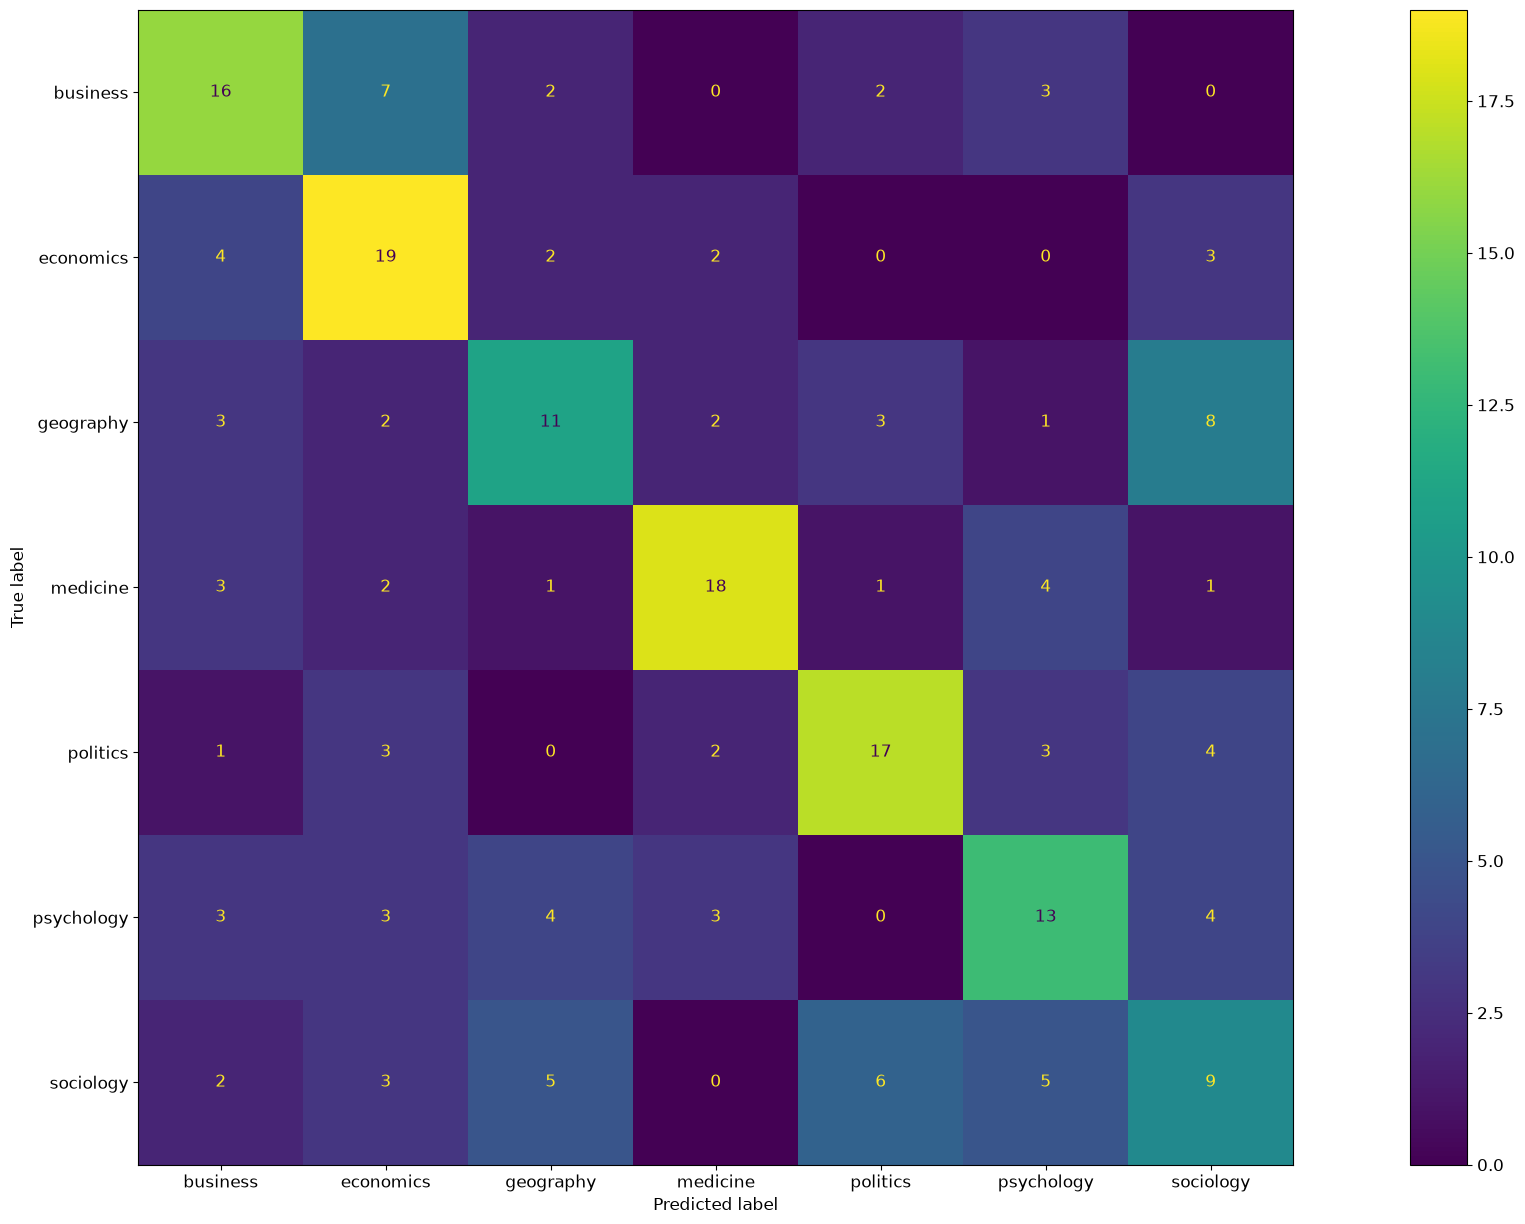

In [8]:
from sklearn import metrics

y_predicted = model.predict(X_test)

print(metrics.classification_report(y_test, y_predicted))
metrics.ConfusionMatrixDisplay.from_predictions(y_test, y_predicted)
None

The recorded run achieves a test macro F1-score of about **0.69** on the MAG sentence-classification dataset, above the historical SciBERT baseline of **0.6571** associated with the [2019 SciBERT work](https://arxiv.org/abs/1903.10676). This compares a linear SVM with one historical baseline; it does not establish current state-of-the-art performance. A broader claim would require a current benchmark with comparable data splits, preprocessing, and metrics.

You might wonder that *"this is great, but besides some utility functions (`clean`, `simple_parallel_map`, ...) what more value does GreatAI add?"*. This would be a valid argument because the scope of GreatAI actually only starts here.

> Not coincidentally, this is the point where the scope of Data Science ends but it's still a grey zone for software engineering.

In order to use this model in production, we have to make it available on some possibly shared infrastructure.

In [9]:
from great_ai import save_model

save_model(model, key="my-domain-predictor")

Environment variable ENVIRONMENT is not set, defaulting to development mode ‼️


Cannot find credentials files, defaulting to using ParallelTinyDbDriver


The selected tracing database (ParallelTinyDbDriver) is not recommended for production


Cannot find credentials files, defaulting to using LargeFileLocal


GreatAI (v0.1.11): configured ✅


  🔩 tracing_database: ParallelTinyDbDriver


  🔩 large_file_implementation: LargeFileLocal


  🔩 is_production: False


  🔩 should_log_exception_stack: True


  🔩 prediction_cache_size: 512


  🔩 dashboard_table_size: 50


You still need to check whether you follow all best practices before trusting your deployment.


> Find out more at https://se-ml.github.io/practices


Fetching cached versions of my-domain-predictor


Fetching cached versions of my-domain-predictor


Fetching cached versions of my-domain-predictor


Model my-domain-predictor uploaded with version 0


'my-domain-predictor:0'

### [Let's continue by finishing the deployment in the next notebook.](https://great-ai.schmelczer.dev/tutorial/deploy)